# NIST TN 1822 — Verif.5.1: Congestion

100 agents in an 8 m x 5 m room with a 2 m corridor leading up to a 2 m exit at the top. Congestion should form at the room exit and at the stair base; steady flow in the corridor between them.

In [1]:
from datetime import datetime
print(f"Executed on {datetime.now().astimezone().strftime('%d %B %Y, %H:%M %Z')}")

Executed on 15 October 2026, 11:40 CEST


In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pedpy
from shapely.geometry import Point, Polygon

from jupedsim_scenarios import load_scenario, run_scenario

In [3]:
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "#f7f7f5",
    "axes.edgecolor": "#3a3a3a",
    "axes.labelcolor": "#1d1d1d",
    "axes.titleweight": "bold",
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
    "figure.figsize": (8, 5),
})

In [4]:
# House style for the V&V figures (plain matplotlib; applied per figure via rc_context).
from matplotlib.colors import to_rgba
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, PathPatch
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.path import Path as MplPath

VV_BLUE, VV_ORANGE, VV_RED, VV_GREEN = "#0072B2", "#E69F00", "#D55E00", "#009E73"
VV_RC = {
    "figure.facecolor": "white", "axes.facecolor": "white", "figure.dpi": 150,
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.grid": True, "grid.color": "#e5e5e5", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": "lightgrey", "axes.labelcolor": "dimgrey",
    "axes.titlecolor": "#333333", "axes.titleweight": "normal", "axes.titlesize": 11,
    "axes.spines.left": False, "axes.spines.bottom": False,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": "dimgrey", "ytick.color": "dimgrey",
    "xtick.major.size": 0, "ytick.major.size": 0,
    "legend.frameon": True, "legend.facecolor": "white", "legend.framealpha": 0.8,
    "legend.edgecolor": "lightgrey", "legend.labelcolor": "dimgrey", "legend.fontsize": 9,
}


def vv_polygon_patch(geom, **kwargs):
    """Matplotlib patch for a shapely (Multi)Polygon, holes included."""
    verts, codes = [], []
    for part in getattr(geom, "geoms", [geom]):
        for ring in [part.exterior, *part.interiors]:
            xy = np.asarray(ring.coords)
            verts.extend(xy)
            codes += [MplPath.MOVETO] + [MplPath.LINETO] * (len(xy) - 2) + [MplPath.CLOSEPOLY]
    return PathPatch(MplPath(verts, codes), **kwargs)


def vv_draw_scenario(ax, scenario, starts=True, pad=0.04):
    """Draw walkable area, exits and start areas of a loaded scenario; return legend handles."""
    ax.add_patch(vv_polygon_patch(scenario.walkable_polygon, facecolor="#eeeeee",
                                  edgecolor="dimgrey", linewidth=1.4, zorder=1))
    handles = [Patch(facecolor="#eeeeee", edgecolor="dimgrey", label="walkable area")]
    if starts:
        for dist in scenario.distributions.values():
            ax.add_patch(MplPolygon(dist["coordinates"], closed=True,
                                    facecolor=to_rgba(VV_BLUE, 0.15), edgecolor=VV_BLUE,
                                    linestyle="--", linewidth=1.2, hatch="..", zorder=2))
        handles.append(Patch(facecolor=to_rgba(VV_BLUE, 0.15), edgecolor=VV_BLUE,
                             linestyle="--", hatch="..", label="start area"))
    for ex in scenario.exits.values():
        ax.add_patch(MplPolygon(ex["coordinates"], closed=True,
                                facecolor=to_rgba(VV_RED, 0.35), edgecolor=VV_RED,
                                linewidth=1.2, hatch="///", zorder=3))
    if scenario.exits:
        handles.append(Patch(facecolor=to_rgba(VV_RED, 0.35), edgecolor=VV_RED,
                             hatch="///", label="exit"))
    minx, miny, maxx, maxy = scenario.walkable_polygon.bounds
    m = pad * max(maxx - minx, maxy - miny)
    ax.set_xlim(minx - m, maxx + m)
    ax.set_ylim(miny - m, maxy + m)
    ax.set_aspect("equal")
    ax.grid(False)
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    return handles

## Load and run

In [5]:
SCENARIO_ZIP = Path("scenario_files") / "Nist-5-1-congestion.zip"
scenario = load_scenario(str(SCENARIO_ZIP))
print(scenario.summary())
result = run_scenario(scenario, seed=42)
df = result.trajectory_dataframe()

Scenario: scenario_files/Nist-5-1-congestion.zip
  Model:         CollisionFreeSpeedModel
  Seed:          42
  Max time:      300s
  Exits:         1
  Distributions: 1
  Stages:        0
  Zones:         0
  Journeys:      1
  Agents:        ~100
  Journey elems: 2
  Route:         1 distribution, 0 checkpoint, 1 exit
  Sequence:      jps-distributions_0 -> jps-exits_0
    jps-distributions_0: 100 agents


## Density at the room exit vs in the corridor

In [6]:
room_exit_box = ((3.0, 5.0), (5.0, 4.5))  # x in 3..5, y in 4.5..5
corridor_box = ((3.0, 17.0), (5.0, 15.0))  # x in 3..5, y in 15..17

def points_in(df, x_range, y_range):
    return df[(df.x >= x_range[0]) & (df.x <= x_range[1]) &
              (df.y >= y_range[0]) & (df.y <= y_range[1])]

AREA_ROOM_EXIT = 2.0 * 0.5
AREA_CORRIDOR = 2.0 * 2.0
rows = []
for frame, sub in df.groupby('frame'):
    rows.append({
        'time_s': frame / result.frame_rate,
        'rho_room_exit': len(points_in(sub, (3.0, 5.0), (4.5, 5.0))) / AREA_ROOM_EXIT,
        'rho_corridor': len(points_in(sub, (3.0, 5.0), (15.0, 17.0))) / AREA_CORRIDOR,
    })
density = pd.DataFrame(rows)
density.head()

,time_s,rho_room_exit,rho_corridor
0,0.0,0.0,0.0
1,0.1,1.0,0.0
2,0.2,2.0,0.0
3,0.3,2.0,0.0
4,0.4,3.0,0.0


## Scenario figure

Room, 2 m wide corridor and the two measuring windows used for the density comparison. The scenario has no stair zone, so only the room-exit part of the NIST expectation is exercised (issue #151).

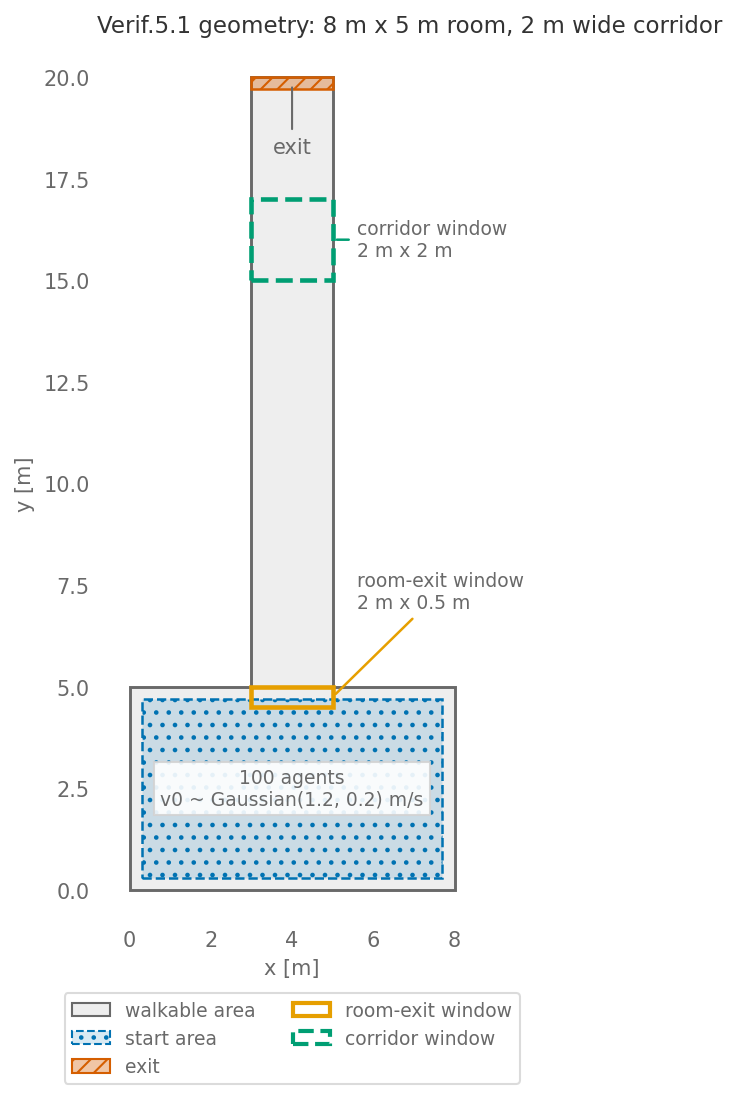

In [7]:
# Scenario geometry from the loaded ZIP; measuring windows from the density cell (corner points).
from matplotlib.patches import Rectangle


def box_xywh(corners):
    xs, ys = [c[0] for c in corners], [c[1] for c in corners]
    return min(xs), min(ys), max(xs) - min(xs), max(ys) - min(ys)


windows = (
    ("room-exit window", room_exit_box, VV_ORANGE, "-"),
    ("corridor window", corridor_box, VV_GREEN, "--"),
)
with plt.rc_context(VV_RC):
    fig, ax = plt.subplots(figsize=(5.2, 7.6))
    handles = vv_draw_scenario(ax, scenario)
    for name, box, color, ls in windows:
        x0, y0, w, h = box_xywh(box)
        ax.add_patch(Rectangle((x0, y0), w, h, fill=False, edgecolor=color, linestyle=ls,
                               linewidth=2.2, zorder=5))
        ax.annotate(f"{name}\n{w:g} m x {h:g} m", xy=(x0 + w, y0 + h / 2),
                    xytext=(x0 + w + 0.6, y0 + h / 2 + (2.6 if h < 1 else 0)), ha="left", va="center",
                    color="dimgrey", fontsize=9, zorder=6,
                    arrowprops={"arrowstyle": "-", "color": color, "lw": 1.2})
        handles.append(Patch(facecolor="none", edgecolor=color, linestyle=ls, linewidth=2.0, label=name))
    for dist in scenario.distributions.values():
        c = Polygon(dist["coordinates"]).centroid
        p = dist["parameters"]
        ax.text(c.x, c.y, f"{p['number']} agents\nv0 ~ Gaussian({p['v0']}, {p['v0_std']}) m/s",
                ha="center", va="center", color="dimgrey", fontsize=9, zorder=6,
                bbox={"facecolor": "white", "edgecolor": "lightgrey", "alpha": 0.9, "pad": 3})
    for ex in scenario.exits.values():
        e = Polygon(ex["coordinates"]).centroid
        ax.annotate("exit", xy=(e.x, e.y), xytext=(0, -26), textcoords="offset points",
                    ha="center", va="top", color="dimgrey",
                    arrowprops={"arrowstyle": "-", "color": "dimgrey"})
    ax.set_title("Verif.5.1 geometry: 8 m x 5 m room, 2 m wide corridor", loc="left")
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=2)
    plt.show()

## Plot densities over time

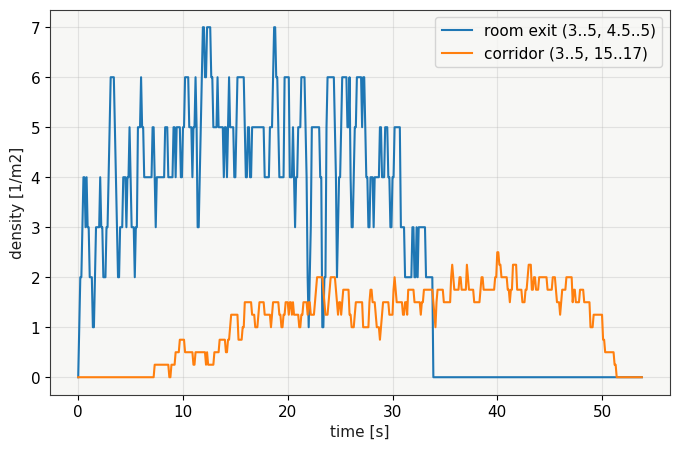

In [8]:
fig, ax = plt.subplots()
ax.plot(density.time_s, density.rho_room_exit, label='room exit (3..5, 4.5..5)')
ax.plot(density.time_s, density.rho_corridor, label='corridor (3..5, 15..17)')
ax.set_xlabel('time [s]'); ax.set_ylabel('density [1/m2]')
ax.legend()
plt.show()

## Acceptance

In [9]:
peak_room = density.rho_room_exit.max()
peak_corridor = density.rho_corridor.max()
print(f'peak room-exit density = {peak_room:.2f} /m2')
print(f'peak corridor density = {peak_corridor:.2f} /m2')
assert peak_room > peak_corridor, (peak_room, peak_corridor)
result.cleanup()

peak room-exit density = 7.00 /m2
peak corridor density = 2.50 /m2


1

## Result figure

Density counted in each window per frame. Acceptance: peak density at the room exit exceeds the peak in the corridor.

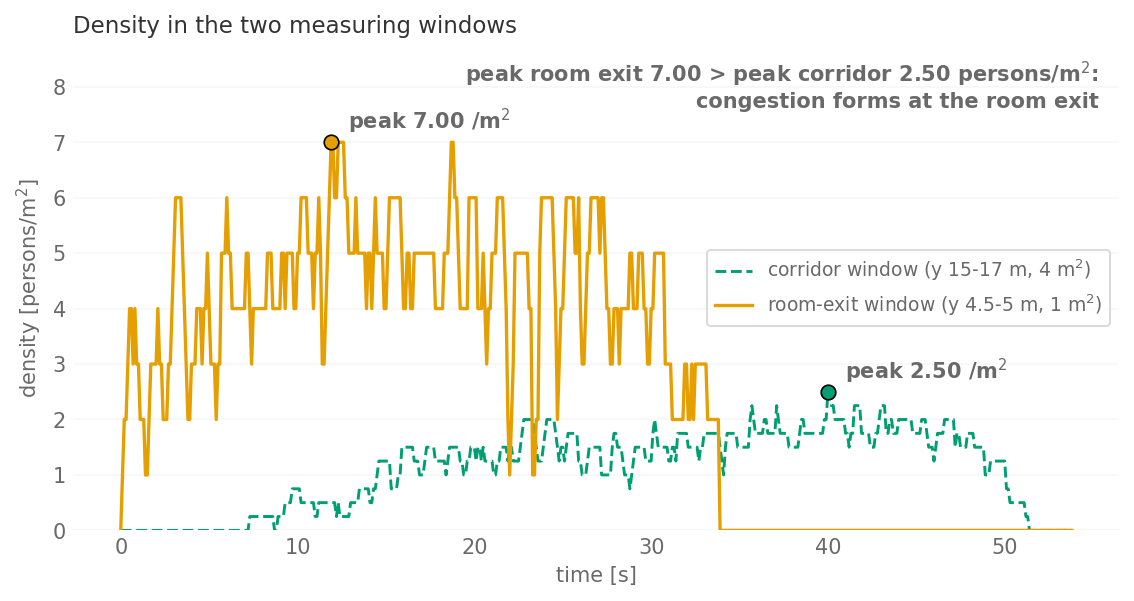

In [10]:
# Peak density over time in the two measuring windows (criterion: room-exit peak > corridor peak).
with plt.rc_context(VV_RC):
    fig, ax = plt.subplots(figsize=(9, 4.2))
    ax.plot(density["time_s"], density["rho_corridor"], color=VV_GREEN, ls="--", lw=1.4,
            label="corridor window (y 15-17 m, 4 m$^2$)")
    ax.plot(density["time_s"], density["rho_room_exit"], color=VV_ORANGE, lw=1.6,
            label="room-exit window (y 4.5-5 m, 1 m$^2$)")
    for col, color, peak, dy in (("rho_room_exit", VV_ORANGE, peak_room, 0.35),
                                 ("rho_corridor", VV_GREEN, peak_corridor, 0.35)):
        t_pk = density.loc[density[col].idxmax(), "time_s"]
        ax.plot(t_pk, peak, "o", color=color, mec="black", mew=0.8, ms=7, zorder=5)
        ax.annotate(f"peak {peak:.2f} /m$^2$", xy=(t_pk, peak), xytext=(8, dy * 18),
                    textcoords="offset points", color="dimgrey", fontweight="semibold")
    ax.set_xlabel("time [s]")
    ax.set_ylabel(r"density [persons/m$^2$]")
    ax.set_title("Density in the two measuring windows", loc="left")
    ax.set_ylim(0, peak_room * 1.25)
    ax.text(0.98, 0.97, f"peak room exit {peak_room:.2f} > peak corridor {peak_corridor:.2f} persons/m$^2$:\n"
            "congestion forms at the room exit",
            transform=ax.transAxes, ha="right", va="top", color="dimgrey", fontweight="semibold")
    ax.legend(loc="center right")
    ax.grid(axis="x", visible=False)
    plt.show()